In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stas

In [2]:
from src.utils.snapshot import latest_snapshot, processed_dir

SNAPSHOT = latest_snapshot()
df = pd.read_parquet(processed_dir(SNAPSHOT) / 'fide_players_active.parquet')
df_colombia = df[df['country'] == "COL"]
df_colombia.info()

<class 'pandas.DataFrame'>
Index: 5437 entries, 3166 to 441417
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   fideid        5437 non-null   int64   
 1   name          5437 non-null   str     
 2   country       5437 non-null   str     
 3   sex           5437 non-null   str     
 4   title         5437 non-null   str     
 5   w_title       5437 non-null   str     
 6   o_title       5437 non-null   str     
 7   rating        1686 non-null   float64 
 8   rapid_rating  4110 non-null   float64 
 9   blitz_rating  3523 non-null   float64 
 10  birthday      5437 non-null   int64   
 11  flag          5437 non-null   str     
 12  es_activo     5437 non-null   bool    
 13  edad          5437 non-null   int64   
 14  categoria     5437 non-null   category
dtypes: bool(1), category(1), float64(3), int64(3), str(7)
memory usage: 797.1 KB


In [3]:
df_colombia.describe().T

,count,mean,std,min,25%,50%,75%,max
fideid,5437.0,9.040150e+07,6.840776e+07,3509265.0,4475615.00,144417829.0,144452993.0,332243778.0
rating,1686.0,1.729273e+03,2.060185e+02,1400.0,1563.25,1707.0,1859.0,2493.0
rapid_rating,4110.0,1.691718e+03,1.757912e+02,1401.0,1557.00,1670.5,1801.0,2513.0
blitz_rating,3523.0,1.698826e+03,1.843075e+02,1400.0,1560.00,1677.0,1814.5,2558.0
birthday,5437.0,1.993395e+03,1.791198e+01,1932.0,1982.00,1998.0,2008.0,2021.0
edad,5437.0,3.260511e+01,1.791198e+01,5.0,18.00,28.0,44.0,94.0


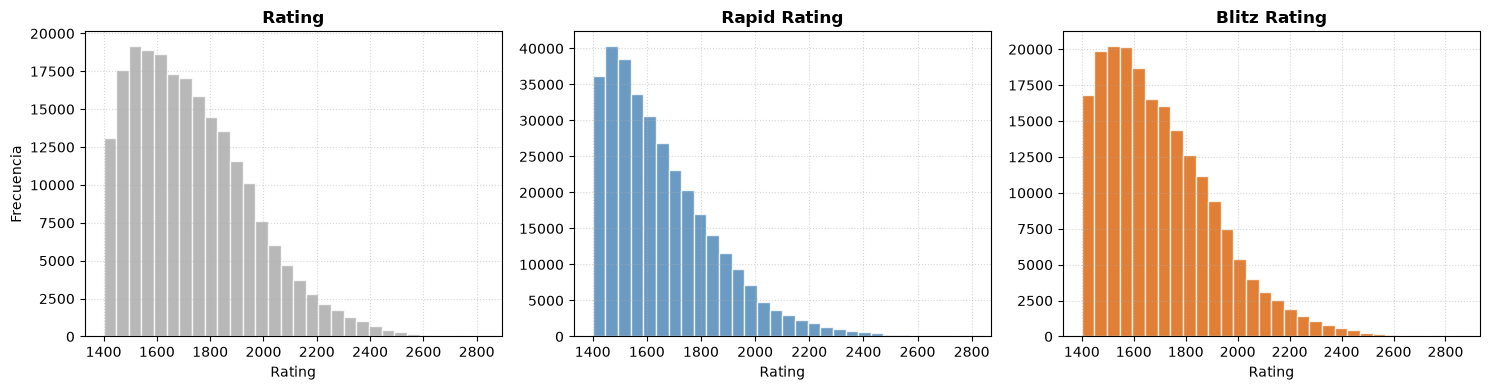

In [4]:
modalidades = [
    'rating',
    'rapid_rating',
    'blitz_rating',
]
colores = ["#A6A6A6", "steelblue", "#D95F02"]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 4), sharey=False)

for i, col in enumerate(modalidades): 
    ax[i].hist(df[col], bins=30, color=colores[i], edgecolor="white", alpha=0.8)
    ax[i].set_title(col.replace("_", " ").title(), fontsize=12, fontweight="bold")
    ax[i].set_xlabel("Rating")
    ax[i].set_ylabel("Frecuencia" if i == 0 else "")
    ax[i].grid(True, linestyle=":", alpha=0.5)

fig.tight_layout()
plt.show()
    


In [5]:
df_elos = df_colombia[['rating', 'rapid_rating', "blitz_rating"]]
df_elos.median().T

rating          1707.0
rapid_rating    1670.5
blitz_rating    1677.0
dtype: float64

In [6]:

filtro =  df_elos.dropna()

print(df_elos.info())
print(' ')
print(filtro.info())

<class 'pandas.DataFrame'>
Index: 5437 entries, 3166 to 441417
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   rating        1686 non-null   float64
 1   rapid_rating  4110 non-null   float64
 2   blitz_rating  3523 non-null   float64
dtypes: float64(3)
memory usage: 169.9 KB
None
 
<class 'pandas.DataFrame'>
Index: 1292 entries, 4643 to 441417
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   rating        1292 non-null   float64
 1   rapid_rating  1292 non-null   float64
 2   blitz_rating  1292 non-null   float64
dtypes: float64(3)
memory usage: 40.4 KB
None


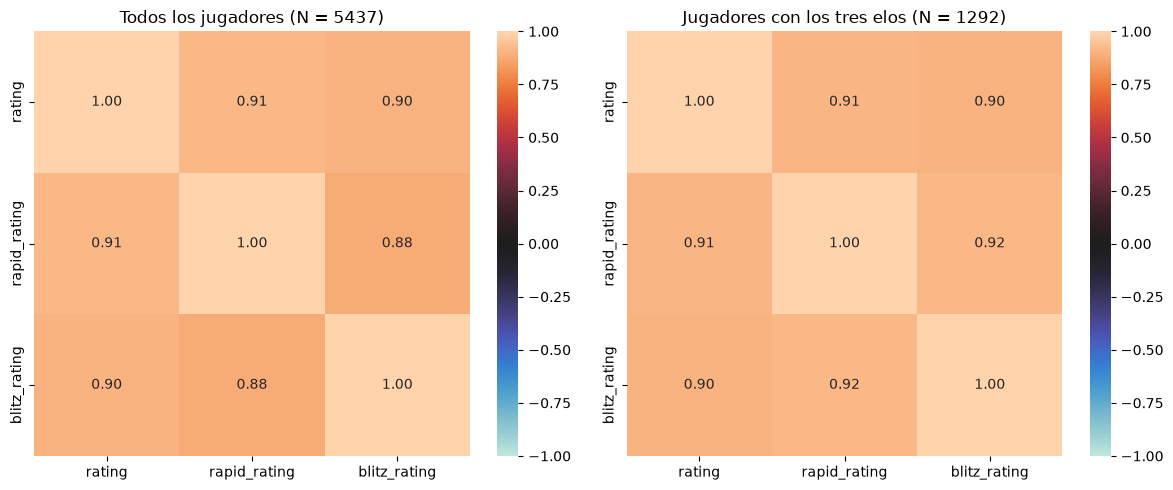

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.heatmap(
    df_elos.corr(),
    annot=True,
    cmap="icefire",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    ax=ax[0],
)

ax[0].set_title(f"Todos los jugadores (N = {len(df_elos)})")

sns.heatmap(
    filtro.corr(),
    annot=True,
    cmap="icefire",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    ax=ax[1],
)
ax[1].set_title(f"Jugadores con los tres elos (N = {len(filtro)})")

fig.tight_layout()
plt.show()

**ESTUDIO**: Este grafico refleja una situacion muy comun en el analisis de correlaciones, cuando en las filas existe valores ausentes (Un jugador que no tiene elo Rating pero si el de blitz y rapida), ocurre que internamente al utilizar DataFrame.corr() pandas exluye el valor faltante, esto ocasiona un error en el resultado, haciendo que el calculo se vea afectado por la variacion en la cantidad de datos. Una forma de resolver esto es filtrar unicamente los jugadores que tienen un elo en las tres modalidades. 

In [8]:
df_conteo_jugadores = df_colombia.groupby('sex')[['rating','rapid_rating',"blitz_rating"]].count().T
df_conteo_jugadores['total'] = df_conteo_jugadores.sum(axis=1)
df_conteo_jugadores

sex,F,M,total
rating,257,1429,1686
rapid_rating,424,3686,4110
blitz_rating,418,3105,3523
